In [7]:
import pandas as pd
import requests
import matplotlib.pyplot as plt

In [8]:
from google.colab import userdata

API_KEY = userdata.get("CENSUS_API_KEY")

In [9]:
url = "https://api.census.gov/data/2024/acs/acs5"

params = {
    "get": "NAME,B19013_001E,B01002_001E",
    "for": "county:*",
    "in": "state:24",
    "key": API_KEY
}

response = requests.get(url, params=params)
response.raise_for_status()

data = response.json()

df = pd.DataFrame(data[1:], columns=data[0])

df = df.rename(columns={
    "NAME": "County",
    "B19013_001E": "Median Income",
    "B01002_001E": "Median Age"
})

df["Median Income"] = pd.to_numeric(df["Median Income"])
df["Median Age"] = pd.to_numeric(df["Median Age"])

display(df)
print("Total county-level jurisdictions:", len(df))

,County,Median Income,Median Age,state,county
0,"Allegany County, Maryland",59603,41.2,24,001
1,"Anne Arundel County, Maryland",124911,39.0,24,003
2,"Baltimore County, Maryland",91768,39.7,24,005
3,"Calvert County, Maryland",133922,40.8,24,009
4,"Caroline County, Maryland",68457,39.9,24,011
5,"Carroll County, Maryland",118211,41.3,24,013
6,"Cecil County, Maryland",92007,40.6,24,015
7,"Charles County, Maryland",122816,38.9,24,017
8,"Dorchester County, Maryland",61839,43.5,24,019
9,"Frederick County, Maryland",122002,39.0,24,021


Total county-level jurisdictions: 24


In [10]:
!pip -q install geopandas

In [11]:
import geopandas as gpd

# Census Bureau 2024 county boundaries
map_url = (
    "https://www2.census.gov/geo/tiger/GENZ2024/"
    "shp/cb_2024_us_county_500k.zip"
)

counties = gpd.read_file(map_url)

# Keep Maryland only
maryland = counties[counties["STATEFP"] == "24"].copy()

# Create matching county IDs
maryland["GEOID"] = maryland["STATEFP"] + maryland["COUNTYFP"]
df["GEOID"] = df["state"] + df["county"]

# Combine Census data with county boundaries
maryland = maryland.merge(df, on="GEOID", how="left")

print("Maryland jurisdictions:", len(maryland))

Maryland jurisdictions: 24


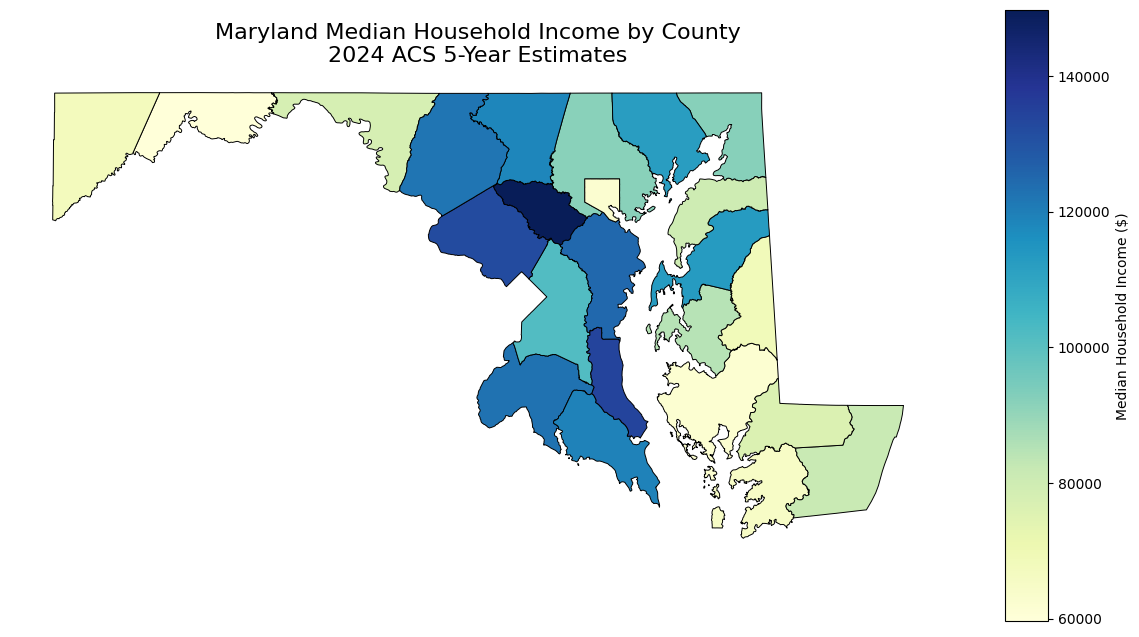

In [12]:
fig, ax = plt.subplots(figsize=(12, 9))

maryland.plot(
    column="Median Income",
    cmap="YlGnBu",
    linewidth=0.7,
    edgecolor="black",
    legend=True,
    legend_kwds={"label": "Median Household Income ($)"},
    ax=ax
)

ax.set_title(
    "Maryland Median Household Income by County\n"
    "2024 ACS 5-Year Estimates",
    fontsize=16
)

ax.axis("off")
plt.tight_layout()
plt.savefig("Maryland_Median_Income.png", dpi=300)
plt.show()

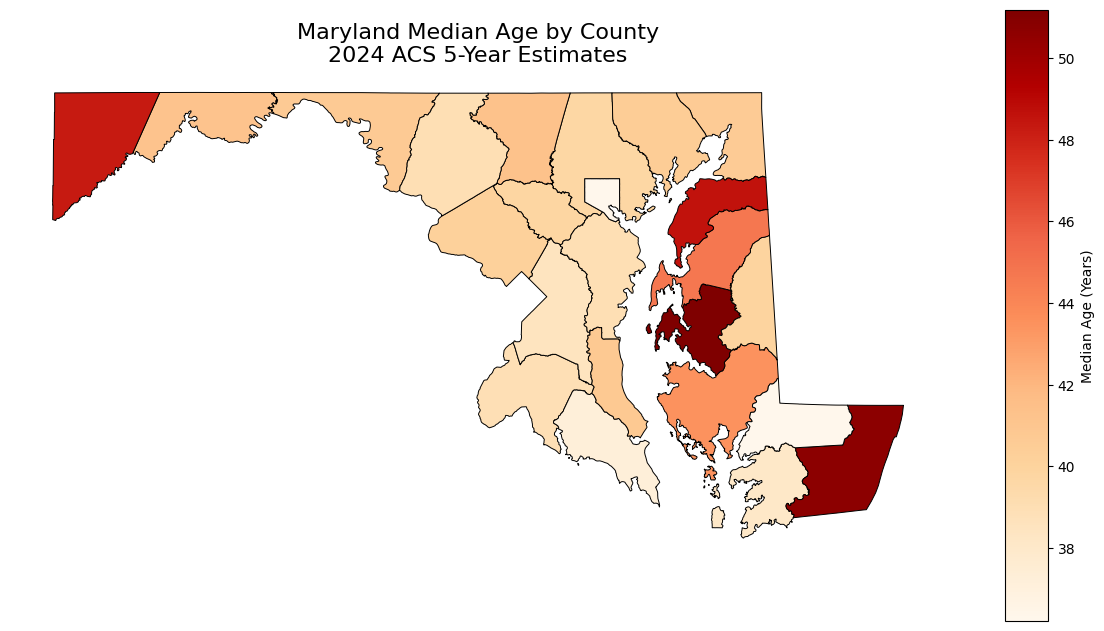

In [13]:
fig, ax = plt.subplots(figsize=(12, 9))

maryland.plot(
    column="Median Age",
    cmap="OrRd",
    linewidth=0.7,
    edgecolor="black",
    legend=True,
    legend_kwds={"label": "Median Age (Years)"},
    ax=ax
)

ax.set_title(
    "Maryland Median Age by County\n"
    "2024 ACS 5-Year Estimates",
    fontsize=16
)

ax.axis("off")
plt.tight_layout()
plt.savefig("Maryland_Median_Age.png", dpi=300)
plt.show()